In [1]:
from pathlib import Path

from cr_knee_fit.analysis import FitConfig
from cr_knee_fit.cr_models.crams import CramsModel

In [2]:
outdir = Path("../out/phase-7/two_le")
config = FitConfig.model_validate_json((outdir / "config-dump.json").read_text())

In [3]:
from cr_knee_fit.fit_data import Data

data = Data.load(config.fit_data_config, verbose=True)

✅ AMS-02 H
✅ AMS-02 N
✅ AMS-02 O
✅ AMS-02 Ne
✅ AMS-02 Mg
✅ AMS-02 Si
✅ AMS-02 S
✅ AMS-02 Fe
✅ DAMPE H
✅ DAMPE He
✅ DAMPE C
❌ DAMPE N: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_N_energy.txt not found.
✅ DAMPE O
❌ DAMPE Ne: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Ne_energy.txt not found.
❌ DAMPE Mg: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Mg_energy.txt not found.
❌ DAMPE Si: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_Si_energy.txt not found.
❌ DAMPE S: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/DAMPE_S_energy.txt not found.
✅ DAMPE Fe
✅ CALET H
❌ CALET N: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_N_energy.txt not found.
✅ CALET O
❌ CALET Ne: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_Ne_energy.txt not found.
❌ CALET Mg: /home/nj-vs-vh/Documents/Science/cr-knee-fit/data/output/CALET_Mg_energy.txt not found.
❌ CALET Si: /home/nj-vs-vh/Documents/Scien

In [4]:
from cr_knee_fit.model import Model

/home/nj-vs-vh/Documents/Science/cr-knee-fit/cr_knee_fit/cr_models/crams.py:37: RuntimeWarning: divide by zero encountered in log10
  components = [np.log10(ip.abundances), ip.slopes]
/home/nj-vs-vh/Documents/Science/cr-knee-fit/cr_knee_fit/cr_models/crams.py:463: RuntimeWarning: divide by zero encountered in log10
  return np.log10(self.crams.compute(self.propagation, self.injection))


logposterior: -231.40539139294998
adjusted logposterior: -231.40539139294998


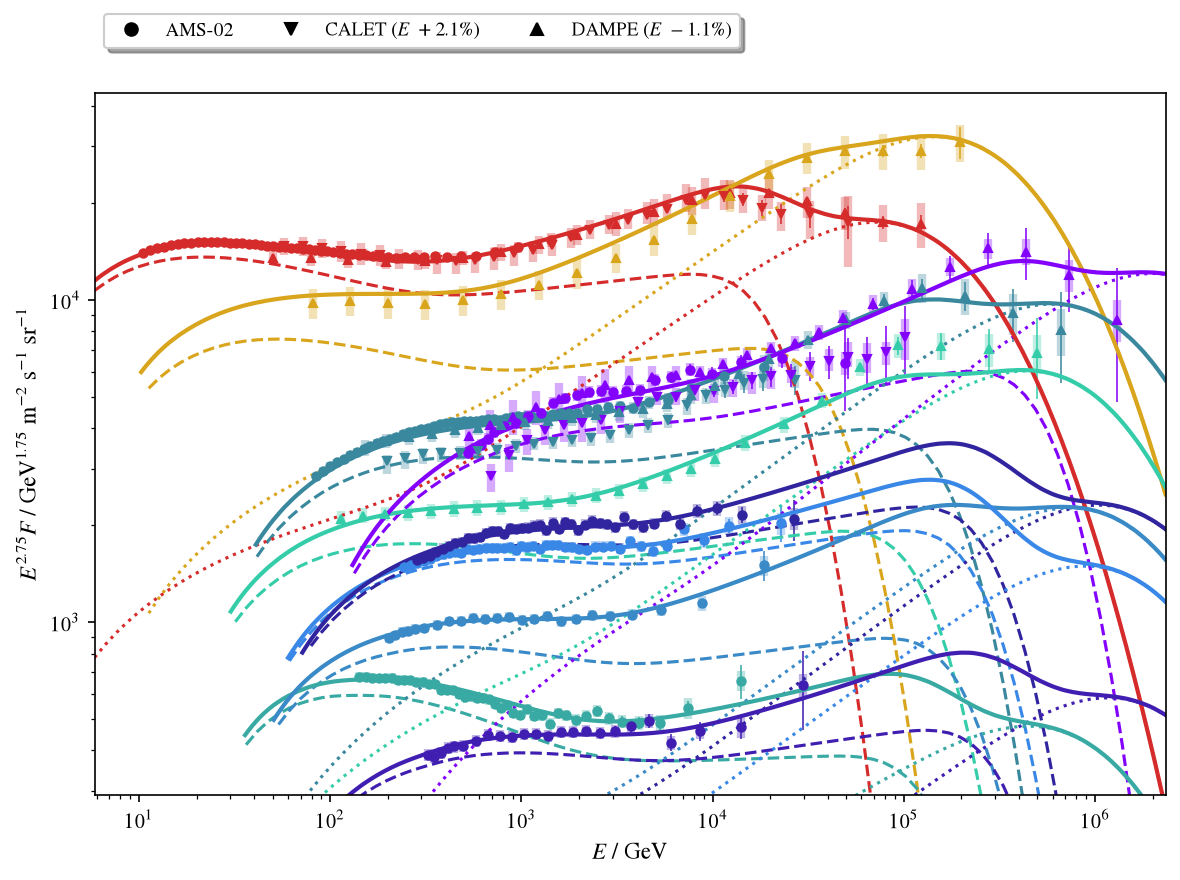

In [15]:
from cr_knee_fit.inference import logposterior

model = Model.load(outdir / "mle-prelim.txt", layout_info=config.model)
assert model is not None
m = model

print("logposterior:", logposterior(m, data, config=config.model))

le_crams, he_crams = m.populations
assert isinstance(le_crams, CramsModel)
assert isinstance(he_crams, CramsModel)

# le_crams.injection.abundances[0] *= 0.95
# he_crams.injection.abundances[1] *= 0.99
# he_crams.injection.abundances[5] *= 0.8
le_crams.clear_crams_cache()

# he_crams.injection.abundances[0] *= 1.5
# he_crams.injection.abundances[1] *= 1.5
# he_crams.injection.abundances[5] *= 1.5
he_crams.clear_crams_cache()

print("adjusted logposterior:", logposterior(m, data, config=config.model))

m.plot_spectra(data, scale=2.75);

In [17]:
model.print_params()

  1.              LE1 v_A = 0.0305
  2.           LE1 lg R_b = 2.51
  3.            LE1 delta = 0.467
  4.      LE1 Delta delta = 0.26
  5.              LE1 D_0 = 3.5
  6.              LE1 phi = 0.779
  7.           LE1 lg q_H = -1.31
  8.          LE1 lg q_He = -1.62
  9.           LE1 lg q_C = -2.3
 10.           LE1 lg q_N = -3.16
 11.           LE1 lg q_O = -1.99
 12.          LE1 lg q_Ne = -2.7
 13.          LE1 lg q_Mg = -2.35
 14.          LE1 lg q_Si = -2.28
 15.           LE1 lg q_S = -3.02
 16.          LE1 lg q_Fe = -1.89
 17.            LE1 gamma = 4.48
 18.       LE1 <lg R_max> = 4.27
 19.  LE1 sigma(lg R_max) = 0.219
 20.           LE2 lg q_H = -2.33
 21.          LE2 lg q_He = -2.24
 22.           LE2 lg q_C = -3.25
 23.           LE2 lg q_N = -4.59
 24.           LE2 lg q_O = -3.11
 25.          LE2 lg q_Ne = -3.8
 26.          LE2 lg q_Mg = -4.04
 27.          LE2 lg q_Si = -3.87
 28.           LE2 lg q_S = -4.53
 29.          LE2 lg q_Fe = -3.29
 30.            LE2 ga

/home/nj-vs-vh/Documents/Science/cr-knee-fit/cr_knee_fit/cr_models/crams.py:37: RuntimeWarning: divide by zero encountered in log10
  components = [np.log10(ip.abundances), ip.slopes]


/home/nj-vs-vh/Documents/Science/cr-knee-fit/cr_knee_fit/cr_models/crams.py:37: RuntimeWarning: divide by zero encountered in log10
  components = [np.log10(ip.abundances), ip.slopes]


(-3.3107834713343047, -1.1921466875405207)

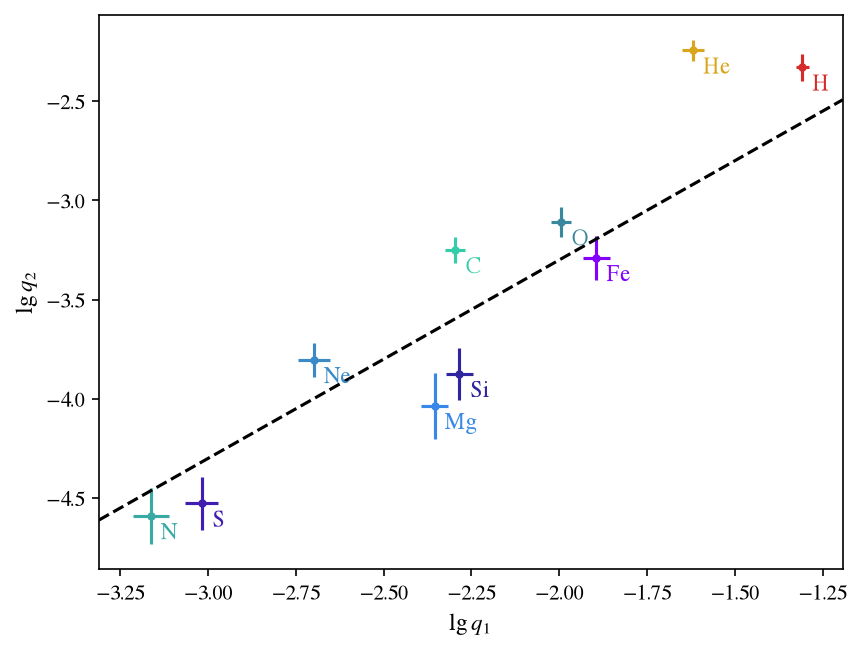

In [53]:
import numpy as np
from matplotlib import pyplot as plt

from cr_knee_fit.elements import Element

elements = [
    Element.H,
    Element.He,
    Element.C,
    Element.N,
    Element.O,
    Element.Ne,
    Element.Mg,
    Element.Si,
    Element.S,
    Element.Fe,
]

le_q_min = 6
le_q_max = 16
he_q_min = 19
he_q_max = 29

fig, ax = plt.subplots()

assert model is not None
assert model.errcov is not None
th = model.pack()
x = th[le_q_min:le_q_max]
xerr = np.sqrt(np.diag(model.errcov)[le_q_min:le_q_max])

y = th[he_q_min:he_q_max]
yerr = np.sqrt(np.diag(model.errcov)[he_q_min:he_q_max])

for i in range(len(x)):
    ax.errorbar(x[i], y[i], xerr=xerr[i], yerr=yerr[i], fmt=".", color=elements[i].color)
    ax.text(x[i] + 0.03, y[i] - 0.03, elements[i].name, color=elements[i].color, va="top")
ax.set_xlabel("$\\lg q_1$")
ax.set_ylabel("$\\lg q_2$")

xlim = ax.get_xlim()
line = ax.plot(xlim, np.array(xlim) - 1.3, "k--")
ax.set_xlim(*xlim)